# 04 — Modèle de régression : consommation d'énergie

**Objectif** : prédire la consommation d'énergie primaire par m² (`conso_5_usages_par_m2_ep`, en kWhEP/m²/an) à partir des caractéristiques du logement, et mesurer honnêtement la qualité du modèle. C'est le modèle de la page « Prédiction » qui affichera la consommation.

**Rappel** : cette consommation est **conventionnelle** (calculée par le diagnostiqueur à partir du bâti, avec un climat et des usages standard). Le modèle apprend à reproduire ce calcul, pas la consommation réelle des habitants.

**Démarche (la même qu'en classification)**
1. Comparer plusieurs modèles par validation croisée groupée par adresse, sur le train.
2. Régler légèrement le meilleur.
3. L'évaluer **une seule fois** sur le test, avec un intervalle d'incertitude.
4. Analyser les erreurs.
5. Comparer avec l'étiquette du modèle de classification, et avec l'étiquette **déduite** de la consommation prédite grâce aux seuils officiels.
6. Tester des variantes (cible transformée, variables) sur le train.
7. Enregistrer le pipeline.

**Règle** : le test n'est utilisé qu'à la section 5.

## 0. Préparation

In [1]:
import json
import os
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, median_absolute_error, r2_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from src.utilis import config
from src.data import transformateurs as tf
from src.utilis import regles_dpe

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4.5)

DOSSIER_FIG = config.RACINE / "reports" / "figures"
ETIQ, CONSO, GES = config.CIBLE_CLASSIFICATION, config.CIBLE_REGRESSION, config.GES_PAR_M2
ORDRE = config.ORDRE_ETIQUETTES
GRAINE = config.GRAINE_ALEATOIRE

N_PLIS = 5            # plis de la validation croisée
REGLER = True         # réglage léger des hyperparamètres du meilleur modèle
N_BOOTSTRAP = 300     # rééchantillonnages pour l'intervalle d'incertitude


def sauver(fig, nom):
    DOSSIER_FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(DOSSIER_FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

## 1. Chargement et contrôles

In [2]:
train = pd.read_csv(config.DATA_TRAITE / "train.csv", low_memory=False)
test = pd.read_csv(config.DATA_TRAITE / "test.csv", low_memory=False)
with open(config.DOSSIER_MODELES / "variables_retenues.json", encoding="utf-8") as f:
    decisions = json.load(f)

VAR_NUM = decisions["variables_numeriques"]
VAR_CAT = decisions["variables_categorielles"]
VARIABLES = VAR_NUM + VAR_CAT

# Consommations aberrantes (marquées dans le notebook 02) : retirées de l'entraînement ET de l'évaluation.
n_train_avant, n_test_avant = len(train), len(test)
train = train[~train["conso_aberrante"].fillna(False).astype(bool)].reset_index(drop=True)
test = test[~test["conso_aberrante"].fillna(False).astype(bool)].reset_index(drop=True)
for d in (train, test):
    d["groupe"] = d["adresse_ban"].fillna(d["numero_dpe"])

assert not set(train["groupe"]) & set(test["groupe"]), "des adresses sont dans le train ET le test"
assert not [v for v in VARIABLES if config.est_colonne_fuite(v)], "colonne issue du calcul du DPE"
assert CONSO not in VARIABLES and GES not in VARIABLES
assert train[CONSO].notna().all() and test[CONSO].notna().all()

print(f"train : {len(train):,} lignes ({n_train_avant - len(train)} aberrante(s) retirée(s))")
print(f"test  : {len(test):,} lignes ({n_test_avant - len(test)} aberrante(s) retirée(s))")
print(f"{len(VARIABLES)} variables : {len(VAR_NUM)} numériques, {len(VAR_CAT)} catégorielles")
print("\nConsommation par m² du train (kWhEP/m²/an) :")
print(train[CONSO].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_string())
print(f"Asymétrie (skewness) : {train[CONSO].skew():.2f}")

train : 39,385 lignes (2 aberrante(s) retirée(s))
test  : 9,839 lignes (0 aberrante(s) retirée(s))
23 variables : 6 numériques, 17 catégorielles

Consommation par m² du train (kWhEP/m²/an) :
count   39,385.000
mean       143.900
std         91.100
min          2.300
5%          34.600
25%         82.100
50%        127.500
75%        184.800
95%        317.000
max        985.700
Asymétrie (skewness) : 1.57


## 2. Comment mesurer la qualité

| Mesure | Ce qu'elle dit |
|---|---|
| **MAE** (mesure principale) | erreur absolue moyenne, en kWhEP/m²/an : « en moyenne, on se trompe de tant » |
| RMSE | comme la MAE, mais les grosses erreurs pèsent davantage ; bien au-dessus de la MAE, elle signale quelques erreurs très grandes |
| R² | part de la variation de la consommation expliquée par le modèle (1 : parfait, 0 : pas mieux que la moyenne) |
| Erreur absolue médiane | l'erreur « typique », peu influencée par les cas extrêmes |
| Biais | erreur moyenne signée : positif si le modèle surestime en moyenne |

Pour juger la MAE, il faut la comparer à la référence (prédire toujours la médiane) et à l'ordre de grandeur de la consommation (médiane autour de 130 kWhEP/m²/an pour l'existant).

In [3]:
def metriques_reg(y_vrai, y_pred):
    y_vrai, y_pred = np.asarray(y_vrai, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "mae": mean_absolute_error(y_vrai, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_vrai, y_pred))),
        "r2": r2_score(y_vrai, y_pred),
        "erreur_absolue_mediane": median_absolute_error(y_vrai, y_pred),
        "biais": float(np.mean(y_pred - y_vrai)),
    }


SCORERS = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
    "erreur_absolue_mediane": "neg_median_absolute_error",
}

## 3. Comparaison de modèles (validation croisée groupée, train uniquement)
- **Référence** : toujours la médiane du train.
- **Régression ridge** : régression linéaire régularisée, avec standardisation et one-hot.
- **Forêt aléatoire** et **gradient boosting** : modèles à base d'arbres, sans standardisation.

Les plis sont définis une fois (groupés par adresse, stratifiés sur l'étiquette) : tous les modèles sont comparés sur les mêmes données.

In [4]:
def pipeline(modele, pour):
    prep = tf.construire_preprocesseur(VAR_NUM, VAR_CAT, pour=pour)
    return Pipeline([("prep", prep), ("modele", modele)])


BASE = "Référence (médiane du train)"
MODELES = {
    BASE: pipeline(DummyRegressor(strategy="median"), "arbres"),
    "Régression ridge": pipeline(Ridge(alpha=1.0), "lineaire"),
    "Forêt aléatoire": pipeline(
        RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=1, random_state=GRAINE), "arbres"),
    "Gradient boosting": pipeline(
        HistGradientBoostingRegressor(early_stopping=False, random_state=GRAINE), "arbres"),
}
POUR = {"Régression ridge": "lineaire", "Forêt aléatoire": "arbres", "Gradient boosting": "arbres"}

cv = StratifiedGroupKFold(n_splits=N_PLIS, shuffle=True, random_state=GRAINE)
plis = list(cv.split(train, train[ETIQ], groups=train["groupe"]))
print("Taille des plis de validation :", [len(i_val) for _, i_val in plis])

Taille des plis de validation : [7877, 7877, 7877, 7877, 7877]


In [5]:
resultats = {}
for nom, modele in MODELES.items():
    res = cross_validate(modele, train[VARIABLES], train[CONSO], cv=plis, scoring=SCORERS, n_jobs=-1)
    resultats[nom] = {
        "mae": -res["test_mae"].mean(), "rmse": -res["test_rmse"].mean(), "r2": res["test_r2"].mean(),
        "erreur_absolue_mediane": -res["test_erreur_absolue_mediane"].mean(),
        "mae_ecart_type": res["test_mae"].std(),
    }
    print(f"{nom} : terminé")

comparaison = pd.DataFrame(resultats).T.sort_values("mae")
MEILLEUR = comparaison.drop(index=BASE)["mae"].idxmin()
print(f"\nMeilleur modèle (MAE en validation croisée) : {MEILLEUR}")
comparaison

Référence (médiane du train) : terminé
Régression ridge : terminé
Forêt aléatoire : terminé
Gradient boosting : terminé

Meilleur modèle (MAE en validation croisée) : Gradient boosting


,mae,rmse,r2,erreur_absolue_mediane,mae_ecart_type
Gradient boosting,27.550,43.743,0.769,16.607,0.836
Forêt aléatoire,29.458,47.288,0.730,17.707,1.100
Régression ridge,36.665,53.414,0.656,26.574,1.069
Référence (médiane du train),65.908,92.454,-0.033,50.740,1.601


**Lecture** : l'écart-type est la variation de la MAE d'un pli à l'autre. Une différence entre deux modèles plus petite que cet écart-type n'est pas nette ; dans ce cas, on préfère le modèle le plus léger, ce qui compte pour le déploiement.

## 4. Réglage léger du meilleur modèle
Petite grille, évaluée par la même validation croisée groupée.

In [6]:
GRILLES = {
    "Régression ridge": {"modele__alpha": [0.1, 1, 10, 100]},
    "Forêt aléatoire": {"modele__min_samples_leaf": [3, 5, 10], "modele__max_features": [0.5, 1.0]},
    "Gradient boosting": {"modele__learning_rate": [0.05, 0.1], "modele__max_leaf_nodes": [15, 31, 63]},
}

if REGLER:
    recherche = GridSearchCV(clone(MODELES[MEILLEUR]), GRILLES[MEILLEUR], scoring="neg_mean_absolute_error",
                             cv=plis, n_jobs=-1, refit=True)
    recherche.fit(train[VARIABLES], train[CONSO])
    meilleurs_parametres = recherche.best_params_
    modele_final = recherche.best_estimator_
    detail = pd.DataFrame(recherche.cv_results_)
    colonnes = [c for c in detail.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    detail["mean_test_score"] = -detail["mean_test_score"]
    print(f"Meilleurs paramètres : {meilleurs_parametres}")
    print(f"MAE en validation croisée : {-recherche.best_score_:.2f}")
    display(detail[colonnes].rename(columns={"mean_test_score": "mae_moyenne", "std_test_score": "ecart_type"})
            .sort_values("mae_moyenne"))
else:
    meilleurs_parametres = {}
    modele_final = clone(MODELES[MEILLEUR]).fit(train[VARIABLES], train[CONSO])
    print("Réglage désactivé : paramètres par défaut.")

Meilleurs paramètres : {'modele__learning_rate': 0.1, 'modele__max_leaf_nodes': 63}
MAE en validation croisée : 27.04


,param_modele__learning_rate,param_modele__max_leaf_nodes,mae_moyenne,ecart_type
5,0.100,63,27.039,0.994
4,0.100,31,27.550,0.836
2,0.050,63,27.876,0.994
3,0.100,15,28.350,0.969
1,0.050,31,28.655,0.858
0,0.050,15,30.047,1.061


## 5. Évaluation finale sur le test
**Une seule fois.** Le test n'a servi à aucun choix.

### 5.1 Résultats globaux

In [7]:
pred_test = modele_final.predict(test[VARIABLES])
base_test = clone(MODELES[BASE]).fit(train[VARIABLES], train[CONSO])

resume_test = pd.DataFrame({
    f"{MEILLEUR} (réglé)": metriques_reg(test[CONSO], pred_test),
    BASE: metriques_reg(test[CONSO], base_test.predict(test[VARIABLES])),
}).T
print(f"Consommation médiane du test : {test[CONSO].median():.0f} kWhEP/m²/an")
resume_test

Consommation médiane du test : 127 kWhEP/m²/an


,mae,rmse,r2,erreur_absolue_mediane,biais
Gradient boosting (réglé),27.044,42.136,0.772,16.432,1.409
Référence (médiane du train),65.002,89.811,-0.034,50.500,-16.284


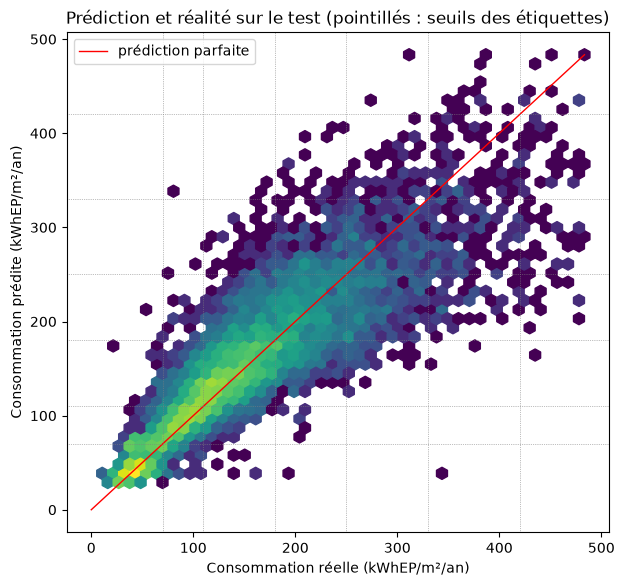

In [8]:
fig, ax = plt.subplots(figsize=(7, 6.5))
limite = float(np.percentile(test[CONSO], 99.5))
ax.hexbin(test[CONSO], pred_test, gridsize=45, extent=(0, limite, 0, limite), mincnt=1, bins="log")
ax.plot([0, limite], [0, limite], color="red", lw=1, label="prédiction parfaite")
for seuil in [s for s, _ in config.SEUILS_ENERGIE_PRIMAIRE if s < limite]:
    ax.axvline(seuil, color="grey", lw=0.5, ls=":")
    ax.axhline(seuil, color="grey", lw=0.5, ls=":")
ax.set_xlabel("Consommation réelle (kWhEP/m²/an)")
ax.set_ylabel("Consommation prédite (kWhEP/m²/an)")
ax.set_title("Prédiction et réalité sur le test (pointillés : seuils des étiquettes)")
ax.legend(loc="upper left")
sauver(fig, "04_prediction_vs_realite")
plt.show()

### 5.2 Où le modèle se trompe-t-il ?

In [9]:
test_eval = test.assign(pred_conso=pred_test)
test_eval["erreur_abs"] = (test_eval["pred_conso"] - test_eval[CONSO]).abs()

par_classe = test_eval.groupby(ETIQ).agg(lignes=(CONSO, "size"), conso_mediane=(CONSO, "median"),
                                         mae=("erreur_abs", "mean")).reindex(ORDRE)
par_classe["mae_relative"] = par_classe["mae"] / par_classe["conso_mediane"]
print("Erreur selon l'étiquette réelle :")
display(par_classe)

tranches = pd.cut(test_eval[CONSO], [0, 70, 110, 180, 250, 330, 420, np.inf],
                  labels=[f"{b}" for b in ["<=70", "70-110", "110-180", "180-250", "250-330", "330-420", ">420"]])
print("Erreur selon la consommation réelle :")
display(test_eval.groupby(tranches, observed=True)["erreur_abs"].agg(["size", "mean"]).rename(
    columns={"size": "lignes", "mean": "mae"}))

Erreur selon l'étiquette réelle :


,lignes,conso_mediane,mae,mae_relative
etiquette_dpe,,,,
A,1779,43.500,11.946,0.275
B,1700,93.000,17.810,0.192
C,3660,135.600,23.150,0.171
D,1591,204.100,33.296,0.163
E,681,278.000,50.522,0.182
F,293,357.000,78.187,0.219
G,135,463.300,144.723,0.312


Erreur selon la consommation réelle :


,lignes,mae
conso_5_usages_par_m2_ep,,
<=70,2002,12.170
70-110,1906,18.598
110-180,3315,23.559
180-250,1521,33.928
250-330,675,50.400
330-420,285,80.016
>420,135,146.241


In [10]:
print("Selon le jeu d'origine :")
display(test_eval.groupby("source_jeu")["erreur_abs"].agg(["size", "mean"]).rename(columns={"size": "lignes", "mean": "mae"}))

print("Selon la méthode de calcul du DPE :")
segments = test_eval.groupby("methode_application_dpe")["erreur_abs"].agg(["size", "mean"]).rename(
    columns={"size": "lignes", "mean": "mae"})
segments.index = segments.index.astype(str).str[:70]
segments.sort_values("lignes", ascending=False)

Selon le jeu d'origine :


,lignes,mae
source_jeu,,
existant,9096,28.461
neuf,743,9.689


Selon la méthode de calcul du DPE :


,lignes,mae
methode_application_dpe,,
dpe appartement individuel,6056,28.639
dpe maison individuelle,2226,28.213
dpe appartement généré à partir des données DPE immeuble,701,23.694
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : apparte,360,11.361
dpe immeuble collectif,219,31.916
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : maison,212,6.972
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : immeubl,32,12.405
dpe issu d'une étude energie environement réglementaire RE2020 bâtimen,30,7.856
dpe issu d'une étude energie environement réglementaire RE2020 bâtimen,2,14.653


### 5.3 Incertitude de l'évaluation
Comme en classification, on rééchantillonne les **adresses** du test avec remise (bootstrap par adresse) : la fourchette indique de combien le score pourrait varier avec un autre échantillon d'adresses.

In [11]:
rng_bs = np.random.default_rng(GRAINE)
blocs = list(test.groupby("groupe").indices.values())
y_reel, y_prevu = test[CONSO].to_numpy(dtype=float), np.asarray(pred_test, dtype=float)

tirages = {"mae": [], "r2": []}
for _ in range(N_BOOTSTRAP):
    choix = rng_bs.integers(0, len(blocs), len(blocs))
    idx = np.concatenate([blocs[k] for k in choix])
    erreur = y_prevu[idx] - y_reel[idx]
    tirages["mae"].append(np.abs(erreur).mean())
    tirages["r2"].append(1 - (erreur ** 2).sum() / ((y_reel[idx] - y_reel[idx].mean()) ** 2).sum())

intervalles = {k: np.percentile(v, [2.5, 97.5]) for k, v in tirages.items()}
for k, (bas, haut) in intervalles.items():
    print(f"{k} : {resume_test.iloc[0][k]:.3f}   intervalle à 95 % : [{bas:.3f} ; {haut:.3f}]")
print(f"\nPour comparaison, MAE en validation croisée sur le train : "
      f"{comparaison.loc[MEILLEUR, 'mae']:.2f} (± {comparaison.loc[MEILLEUR, 'mae_ecart_type']:.2f})")

mae : 27.044   intervalle à 95 % : [25.835 ; 28.432]
r2 : 0.772   intervalle à 95 % : [0.754 ; 0.791]

Pour comparaison, MAE en validation croisée sur le train : 27.55 (± 0.84)


## 6. De la consommation à l'étiquette
L'étiquette DPE se déduit de la consommation (et des émissions de GES). On compare trois façons d'obtenir l'étiquette sur le même test :

| Méthode | Principe |
|---|---|
| Classification (notebook 03) | le modèle prédit directement l'étiquette |
| **Régression puis seuils** | on prédit la consommation, puis on applique les seuils d'énergie primaire |
| Plafonds | étiquette recalculée à partir de la **vraie** consommation : ce que la méthode pourrait atteindre avec une régression parfaite |

La méthode « régression puis seuils » n'utilise que la consommation : elle ne voit pas les cas où ce sont les **émissions de GES** qui décident de l'étiquette (13,8 % des cas dans nos données), d'où un plafond inférieur à 100 %.

In [12]:
def metriques_etiquette(y_vrai, y_pred):
    rang = {l: i for i, l in enumerate(ORDRE)}
    ecart = np.abs(pd.Series(np.asarray(y_vrai)).map(rang).to_numpy() - pd.Series(np.asarray(y_pred)).map(rang).to_numpy())
    return {
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", labels=ORDRE, zero_division=0),
        "exactitude": accuracy_score(y_vrai, y_pred),
        "exactitude_equilibree": balanced_accuracy_score(y_vrai, y_pred),
        "a_une_classe_pres": float((ecart <= 1).mean()),
    }


etiq_deduite = regles_dpe.etiquette_energie(pd.Series(pred_test, index=test.index))
etiq_vraie_conso = regles_dpe.etiquette_energie(test[CONSO])
etiq_vraie_conso_ges = regles_dpe.etiquette_theorique(test[CONSO], test[GES])
masque_ges = test[GES].notna()

lignes = {"Régression puis seuils (consommation prédite)": metriques_etiquette(test[ETIQ], etiq_deduite)}
lignes["Plafond : vraie consommation, seuils d'énergie"] = metriques_etiquette(test[ETIQ], etiq_vraie_conso)
lignes["Plafond : vraie consommation et vrais GES"] = metriques_etiquette(
    test.loc[masque_ges, ETIQ], etiq_vraie_conso_ges.loc[masque_ges])

chemin_json_classif = config.DOSSIER_MODELES / "metriques_classification.json"
if chemin_json_classif.exists():
    with open(chemin_json_classif, encoding="utf-8") as f:
        lignes_classif = {"Classification directe (notebook 03)": json.load(f)["test"]}
    comparaison_etiquette = pd.DataFrame({**lignes_classif, **lignes}).T
else:
    comparaison_etiquette = pd.DataFrame(lignes).T
    print("metriques_classification.json introuvable : comparaison avec la classification omise.")
comparaison_etiquette

,f1_macro,exactitude,exactitude_equilibree,a_une_classe_pres
Classification directe (notebook 03),0.511,0.637,0.513,0.949
Régression puis seuils (consommation prédite),0.485,0.611,0.472,0.950
"Plafond : vraie consommation, seuils d'énergie",0.872,0.879,0.877,0.983
Plafond : vraie consommation et vrais GES,0.944,0.959,0.956,0.997


**Lecture** : si « régression puis seuils » dépasse la classification directe, la consommation est le bon levier pour l'étiquette. Les deux lignes « plafond » indiquent la marge théorique. Les résultats de la classification ont été calculés sur le même découpage ; seules les consommations aberrantes (très peu de lignes) ont été retirées ici.

In [ ]:
cm_deduite = pd.crosstab(test[ETIQ], etiq_deduite).reindex(index=ORDRE, columns=ORDRE, fill_value=0)
print("Étiquette réelle (lignes) contre étiquette déduite de la consommation prédite (colonnes) :")
cm_deduite

## 7. Tests de variantes (validation croisée sur le train)
Mêmes plis, mêmes paramètres. Une différence plus petite que l'écart-type entre plis n'est pas nette : on garde alors l'option la plus simple.

- **Cible en logarithme** : la consommation est asymétrique ; prédire son logarithme puis revenir à l'échelle d'origine peut aider certains modèles.
- **Sans les colonnes ajoutées à l'étape 1** et **sans les types de générateurs** : mesure l'apport de ces colonnes.

In [13]:
def nouveau_modele(num, cat, log=False):
    modele = clone(MODELES[MEILLEUR])
    modele.set_params(**meilleurs_parametres)
    modele.set_params(prep=tf.construire_preprocesseur(num, cat, pour=POUR[MEILLEUR]))
    if log:
        modele = TransformedTargetRegressor(regressor=modele, func=np.log1p, inverse_func=np.expm1)
    return modele


NUM_CONNUES = set(config.VARIABLES_CANDIDATES_NUMERIQUES + tf.VARIABLES_CREEES_NUMERIQUES)


def separer(variables):
    num = [v for v in variables if v in NUM_CONNUES]
    return num, [v for v in variables if v not in NUM_CONNUES]


def mae_en_validation_croisee(variables, log=False):
    num, cat = separer(variables)
    maes = []
    for i_fit, i_val in plis:
        fit_v, val_v = train.iloc[i_fit], train.iloc[i_val]
        modele_v = nouveau_modele(num, cat, log).fit(fit_v[variables], fit_v[CONSO])
        maes.append(mean_absolute_error(val_v[CONSO], modele_v.predict(val_v[variables])))
    return np.array(maes)


NOUVELLES_COLONNES = [
    "numero_etage_appartement", "nombre_niveau_immeuble", "nombre_appartement", "surface_habitable_immeuble",
    "volume_stockage_generateur_n1_ecs_n1", "surface_chauffee_installation_chauffage_n1",
    "type_generateur_chauffage_principal", "type_emetteur_installation_chauffage_n1",
    "type_generateur_n1_installation_n1", "type_installation_ecs", "type_generateur_chauffage_principal_ecs",
    "type_generateur_n1_ecs_n1", "typologie_logement", "position_logement_dans_immeuble",
    "isolation_toiture", "inertie_lourde", "type_generateur_froid", "protection_solaire_exterieure",
    "presence_brasseur_air", "presence_production_pv", "type_installation_solaire_n1",
]
GENERATEURS = ["type_generateur_n1_installation_n1", "type_generateur_n1_ecs_n1",
               "type_emetteur_installation_chauffage_n1"]

variantes = {
    "référence": (VARIABLES, False),
    "cible en logarithme": (VARIABLES, True),
    "sans les colonnes ajoutées à l'étape 1": ([v for v in VARIABLES if v not in NOUVELLES_COLONNES], False),
    "sans les types de générateurs et d'émetteurs": ([v for v in VARIABLES if v not in GENERATEURS], False),
}

lignes_v = {}
for nom, (variables, log) in variantes.items():
    maes = mae_en_validation_croisee(variables, log)
    lignes_v[nom] = {"mae": maes.mean(), "ecart_type_entre_plis": maes.std()}
    print(f"{nom} : terminé")

sensibilite = pd.DataFrame(lignes_v).T
sensibilite["difference_avec_reference"] = sensibilite["mae"] - sensibilite.iloc[0]["mae"]
sensibilite

référence : terminé
cible en logarithme : terminé
sans les colonnes ajoutées à l'étape 1 : terminé
sans les types de générateurs et d'émetteurs : terminé


,mae,ecart_type_entre_plis,difference_avec_reference
référence,27.039,0.994,0.000
cible en logarithme,26.445,0.910,-0.595
sans les colonnes ajoutées à l'étape 1,36.831,0.780,9.791
sans les types de générateurs et d'émetteurs,30.056,0.675,3.017


## 8. Sauvegarde

In [14]:
config.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
chemin_modele = config.DOSSIER_MODELES / "modele_regression.joblib"
joblib.dump(modele_final, chemin_modele, compress=3)

taille_mo = os.path.getsize(chemin_modele) / 1e6
print(f"Taille du modèle enregistré : {taille_mo:.1f} Mo")
if taille_mo > 50:
    print("ATTENTION : fichier volumineux (GitHub avertit à 50 Mo et refuse à 100 Mo). "
          "Ne pas le committer ; préférer un modèle plus léger (gradient boosting, moins d'arbres).")

# Contrôle : le pipeline rechargé donne exactement les mêmes prédictions.
recharge = joblib.load(chemin_modele)
assert np.allclose(recharge.predict(test[VARIABLES]), pred_test)

bilan = {
    "modele": MEILLEUR,
    "parametres": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in meilleurs_parametres.items()},
    "variables": VARIABLES,
    "taille_fichier_mo": round(taille_mo, 1),
    "validation_croisee_train": comparaison.loc[MEILLEUR].to_dict(),
    "test": resume_test.iloc[0].to_dict(),
    "test_intervalle_95": {k: [float(b), float(h)] for k, (b, h) in intervalles.items()},
    "test_reference": resume_test.loc[BASE].to_dict(),
    "etiquette_deduite_test": comparaison_etiquette.loc["Régression puis seuils (consommation prédite)"].to_dict(),
}
with open(config.DOSSIER_MODELES / "metriques_regression.json", "w", encoding="utf-8") as f:
    json.dump(bilan, f, ensure_ascii=False, indent=2)

comparaison.to_csv(config.DATA_TRAITE / "comparaison_modeles_regression.csv")
sensibilite.to_csv(config.DATA_TRAITE / "sensibilite_regression.csv")
print("Fichiers écrits :")
for chemin in [chemin_modele, config.DOSSIER_MODELES / "metriques_regression.json",
               config.DATA_TRAITE / "comparaison_modeles_regression.csv",
               config.DATA_TRAITE / "sensibilite_regression.csv"]:
    print(" -", chemin.relative_to(config.RACINE))

Taille du modèle enregistré : 0.3 Mo
Fichiers écrits :
 - models\modele_regression.joblib
 - models\metriques_regression.json
 - data\processed\comparaison_modeles_regression.csv
 - data\processed\sensibilite_regression.csv


## 9. Synthèse et pistes selon les résultats
À compléter après exécution.

| Question | Réponse (chiffres) |
|---|---|
| Meilleur modèle et réglages | |
| MAE : validation croisée / test / intervalle à 95 % | |
| MAE de référence (médiane) et gain | |
| R² | |
| Erreur selon la classe réelle (classes E à G) | |
| Étiquette déduite : F1 macro / exactitude, contre la classification | |
| Plafond de l'approche « consommation puis seuils » | |
| Effet de la cible en logarithme | |
| Taille du fichier du modèle | |

